<a href="https://colab.research.google.com/github/maxiangt/MSSP607/blob/main/Modules/Week_11/MSSP607_WEEK_11_CA_Districts.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

## 0. Setup

In [4]:
!pip install geopandas mapclassify -q
import geopandas as gpd
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

In [5]:
import os
required_files = ["california-congressional-districts.geojson", "CA_Legislative_Districts.csv"]
if any(not os.path.exists(p) for p in required_files):
    from google.colab import files
    files.upload()
for p in required_files:
    if not os.path.exists(p):
        raise FileNotFoundError(f"Missing required file: {p}")

cong = gpd.read_file("california-congressional-districts.geojson")
pop = pd.read_csv("CA_Legislative_Districts.csv", encoding="utf-8-sig", dtype={"DISTRICT": str})

print(cong.shape, cong.crs)
print(pop.shape)
cong.head()

(53, 4) EPSG:4326
(52, 25)


,Name,description,descriptio,geometry
0,01,None,,"MULTIPOLYGON (((-120.07192 41.99495, -120.0010..."
1,02,None,,"MULTIPOLYGON (((-123.69821 41.81719, -123.6967..."
2,03,None,,"MULTIPOLYGON (((-121.667 39.30511, -121.63015 ..."
3,04,None,,"MULTIPOLYGON (((-120.37731 37.61679, -120.3823..."
4,05,None,,"MULTIPOLYGON (((-122.16384 38.64288, -122.1659..."


## Task 1.

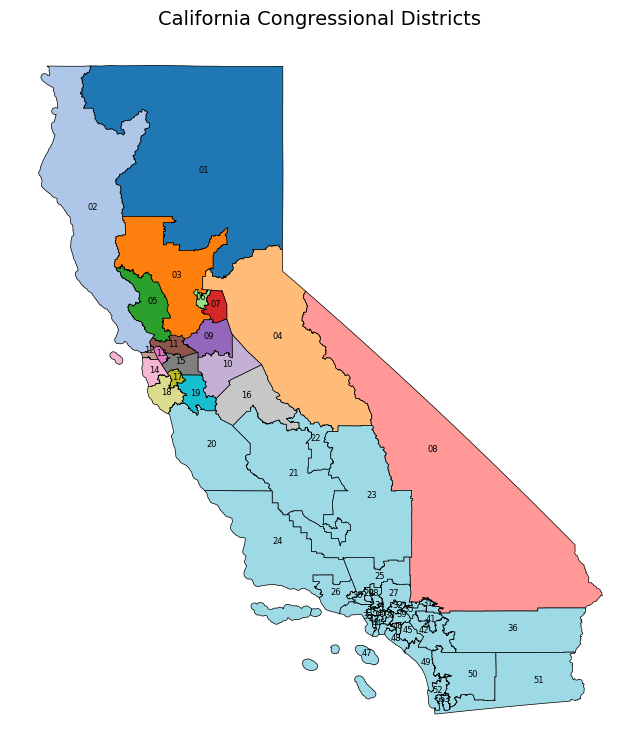

In [6]:
fig, ax = plt.subplots(figsize=(8, 10))
cong.plot(ax=ax, column="Name", cmap="tab20", edgecolor="black", linewidth=0.5)

# label each district with its number
for _, row in cong.iterrows():
    pt = row.geometry.representative_point()
    ax.annotate(row["Name"], (pt.x, pt.y), ha="center", fontsize=6)

ax.set_title("California Congressional Districts", fontsize=14)
ax.axis("off")
plt.show()

## Task 2.
The geospatial file has no population, so I join the CSV to it using the district number (`Name` in the GeoJSON = `DISTRICT` in the CSV).

In [7]:
merged = cong.merge(pop, left_on="Name", right_on="DISTRICT", how="left")

print("Districts without CSV data:", merged.loc[merged["POPULATION"].isna(), "Name"].tolist())
print("Population range:", merged["POPULATION"].min(), "to", merged["POPULATION"].max())

Districts without CSV data: ['53']
Population range: 760065.0 to 760067.0


**Data limitation:** CSV has 52 regions, and GeoJSON has 53 (California increased from 53 seats to 52 seats after the 2020 census), so these two files seem to come from different regional maps. District 53 has no population value and is indicated in gray. Therefore, without verifying the matching by regional numbers, the following map should be regarded as a technical demonstration rather than the result of precise population division by boundaries. The next cell compares the mapping area of each region with the area in the CSV as a check.

In [8]:
check = merged.to_crs(epsg=3310)
check["map_area_sqmi"] = check.area / 2.59e6
check["area_ratio"] = (check["map_area_sqmi"] / check["AREA"]).round(2)
check[["Name", "NAME", "map_area_sqmi", "AREA", "area_ratio"]].sort_values("area_ratio").head(10)

,Name,NAME,map_area_sqmi,AREA,area_ratio
13,13,OKLND,145.937430,6346.92,0.02
47,48,WSTCST,254.848670,3636.15,0.07
25,25,AVSCV,1702.449085,12356.44,0.14
39,40,DOWNTOWN,58.366261,393.34,0.15
18,18,SNMSC,823.483093,4606.63,0.18
4,05,NEBAY,1854.137898,9962.22,0.19
40,41,RVMVN,318.190222,1346.05,0.24
19,19,SNACL,921.832205,3583.48,0.26
22,22,FRSNO,1168.943656,4320.21,0.27
28,28,SGMFH,219.389149,789.86,0.28


A ratio close to 1 indicates that the boundary and the CSV line may describe the same area; The index in many regions is far below 1, which supports the above warning. Each CSV district also has approximately 760,066 people, so the population remains almost unchanged (with a difference of 1-2 people). I also drew a map of the referendum age population (CVAP), the latter of which varies more significantly.

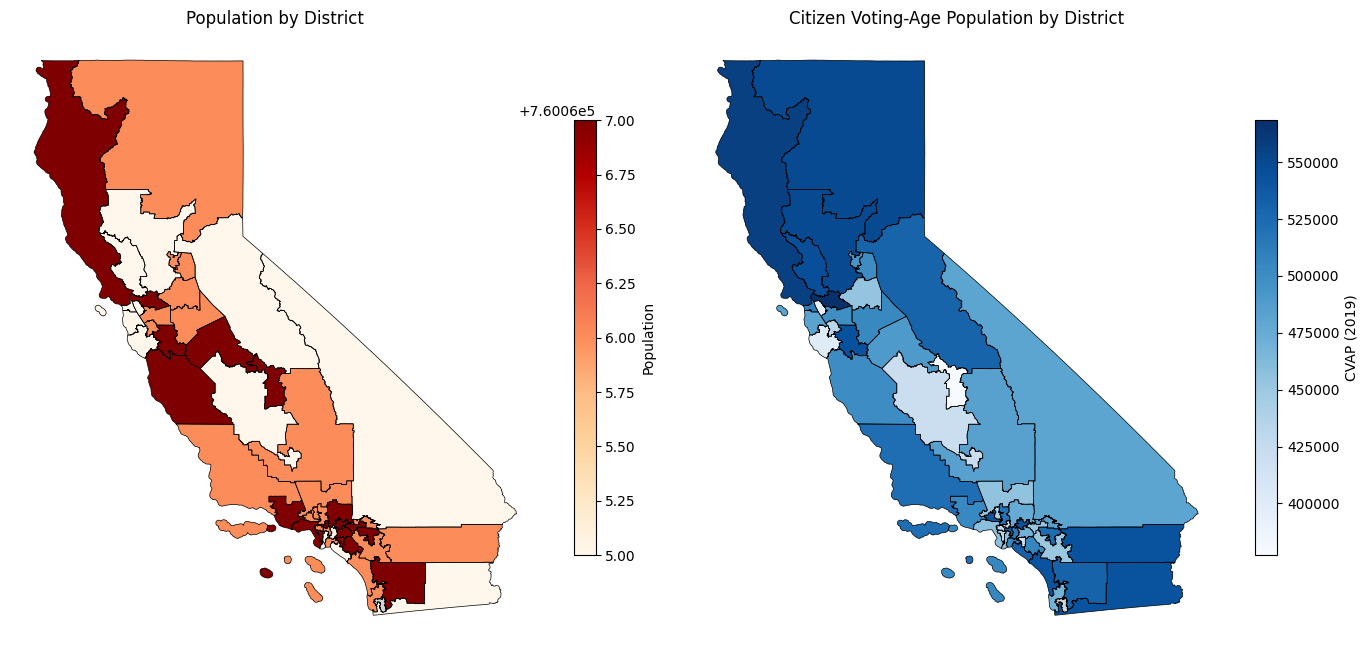

In [9]:
fig, axes = plt.subplots(1, 2, figsize=(14, 9))

merged.plot(ax=axes[0], column="POPULATION", cmap="OrRd", legend=True,
            legend_kwds={"label": "Population", "shrink": 0.5},
            missing_kwds={"color": "lightgrey", "label": "No data"})
merged.boundary.plot(ax=axes[0], edgecolor="black", linewidth=0.5)
axes[0].set_title("Population by District")

merged.plot(ax=axes[1], column="CVAP_19", cmap="Blues", legend=True,
            legend_kwds={"label": "CVAP (2019)", "shrink": 0.5},
            missing_kwds={"color": "lightgrey"})
merged.boundary.plot(ax=axes[1], edgecolor="black", linewidth=0.5)
axes[1].set_title("Citizen Voting-Age Population by District")

for ax in axes:
    ax.axis("off")
plt.tight_layout()
plt.show()

## Task 3.
This is a **schematic** heatmap: each district's whole population is placed at its geometric center and summed in hexagonal cells. It shows where districts (and so people) cluster, but it is not true population density, because it ignores how people are spread inside a district. District 53 is excluded because it has no population data.

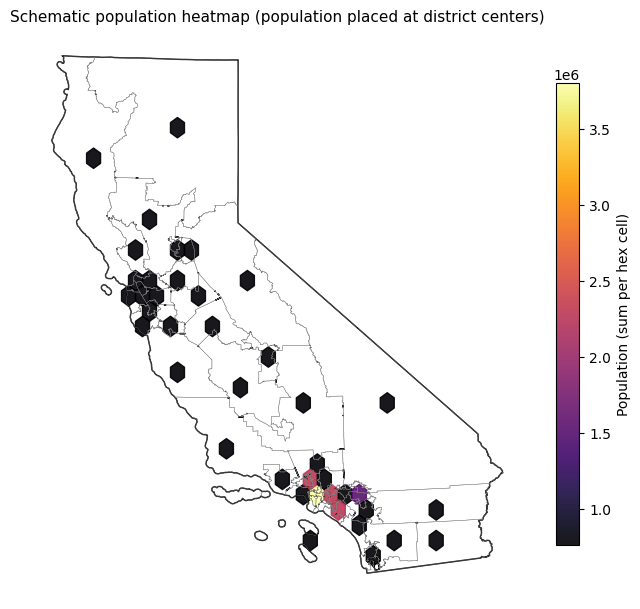

In [10]:
proj = merged.dropna(subset=["POPULATION"]).to_crs(epsg=3310)   # drop district 53 (no data), California Albers (meters)
state = proj.dissolve()                  # outline of the whole state

cent = proj.geometry.centroid
weights = proj["POPULATION"]

fig, ax = plt.subplots(figsize=(8, 10))
hb = ax.hexbin(cent.x, cent.y, C=weights, reduce_C_function=np.sum,
               gridsize=25, cmap="inferno", mincnt=1, alpha=0.9)
state.boundary.plot(ax=ax, edgecolor="black", linewidth=1)
proj.boundary.plot(ax=ax, edgecolor="grey", linewidth=0.3)
plt.colorbar(hb, ax=ax, shrink=0.6, label="Population (sum per hex cell)")
ax.set_title("Schematic population heatmap (population placed at district centers)", fontsize=11)
ax.axis("off")
plt.show()

## Summary
Districts are clustered most heavily in the Bay Area and Southern California, while a few large districts cover the north and east. Limitations: (1) the CSV (52 districts) and the GeoJSON (53 districts) seem to be different maps, so the population-to-boundary match is unverified; (2) the heatmap is schematic, not true population density; (3) population is nearly equal across districts by design.